In [31]:
import numpy as np
import matplotlib.pyplot as plt
import cv2
import os
import tensorflow as tf
from PIL import Image

from sklearn.model_selection import train_test_split

from tensorflow.keras.utils import normalize, to_categorical
from tensorflow.keras.models import Sequential, load_model
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Activation, Dropout, Flatten, Dense 

In [32]:
image_directory='datasets/'
 
no_tumor_images=os.listdir(image_directory+"no")  
yes_tumor_images=os.listdir(image_directory+ 'yes/')

print('No Tumor: ', len(no_tumor_images))
print('Tumor: ',len(yes_tumor_images))

# path="no0.jpg"

# print(path.split(".")[1]) 

No Tumor:  1500
Tumor:  1500


In [33]:
dataset=[]
label=[]

INPUT_SIZE=64

In [34]:
for i , image_name in enumerate(no_tumor_images):
    if(image_name.split('.')[1]=='jpg'):
        image=cv2.imread(image_directory+'no/'+image_name)
        image=Image.fromarray(image,'RGB')
        image=image.resize((INPUT_SIZE,INPUT_SIZE))
        dataset.append(np.array(image))
        label.append(0)

In [35]:
for i , image_name in enumerate(yes_tumor_images):
    if(image_name.split('.')[1]=='jpg'):
        image=cv2.imread(image_directory+'yes/'+image_name)
        image=Image.fromarray(image, 'RGB')
        image=image.resize((INPUT_SIZE,INPUT_SIZE))
        dataset.append(np.array(image))
        label.append(1)

In [36]:
print(dataset)

[array([[[0, 0, 0],
        [0, 0, 0],
        [0, 0, 0],
        ...,
        [0, 0, 0],
        [0, 0, 0],
        [0, 0, 0]],

       [[0, 0, 0],
        [0, 0, 0],
        [0, 0, 0],
        ...,
        [0, 0, 0],
        [0, 0, 0],
        [0, 0, 0]],

       [[0, 0, 0],
        [0, 0, 0],
        [0, 0, 0],
        ...,
        [0, 0, 0],
        [0, 0, 0],
        [0, 0, 0]],

       ...,

       [[0, 0, 0],
        [0, 0, 0],
        [0, 0, 0],
        ...,
        [0, 0, 0],
        [0, 0, 0],
        [0, 0, 0]],

       [[0, 0, 0],
        [0, 0, 0],
        [0, 0, 0],
        ...,
        [0, 0, 0],
        [0, 0, 0],
        [0, 0, 0]],

       [[0, 0, 0],
        [0, 0, 0],
        [0, 0, 0],
        ...,
        [0, 0, 0],
        [0, 0, 0],
        [0, 0, 0]]], dtype=uint8), array([[[0, 0, 0],
        [0, 0, 0],
        [0, 0, 0],
        ...,
        [0, 0, 0],
        [0, 0, 0],
        [0, 0, 0]],

       [[0, 0, 0],
        [0, 0, 0],
        [0, 0, 0],
        ...,

In [37]:
print(label)

[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 

In [38]:
dataset=np.array(dataset)
label=np.array(label)

In [39]:
print('Dataset: ',len(dataset))
print('Label: ',len(label))

Dataset:  3000
Label:  3000


In [40]:
print(dataset)

[[[[ 0  0  0]
   [ 0  0  0]
   [ 0  0  0]
   ...
   [ 0  0  0]
   [ 0  0  0]
   [ 0  0  0]]

  [[ 0  0  0]
   [ 0  0  0]
   [ 0  0  0]
   ...
   [ 0  0  0]
   [ 0  0  0]
   [ 0  0  0]]

  [[ 0  0  0]
   [ 0  0  0]
   [ 0  0  0]
   ...
   [ 0  0  0]
   [ 0  0  0]
   [ 0  0  0]]

  ...

  [[ 0  0  0]
   [ 0  0  0]
   [ 0  0  0]
   ...
   [ 0  0  0]
   [ 0  0  0]
   [ 0  0  0]]

  [[ 0  0  0]
   [ 0  0  0]
   [ 0  0  0]
   ...
   [ 0  0  0]
   [ 0  0  0]
   [ 0  0  0]]

  [[ 0  0  0]
   [ 0  0  0]
   [ 0  0  0]
   ...
   [ 0  0  0]
   [ 0  0  0]
   [ 0  0  0]]]


 [[[ 0  0  0]
   [ 0  0  0]
   [ 0  0  0]
   ...
   [ 0  0  0]
   [ 0  0  0]
   [ 0  0  0]]

  [[ 0  0  0]
   [ 0  0  0]
   [ 0  0  0]
   ...
   [ 0  0  0]
   [ 0  0  0]
   [ 0  0  0]]

  [[ 0  0  0]
   [ 0  0  0]
   [ 0  0  0]
   ...
   [ 0  0  0]
   [ 0  0  0]
   [ 0  0  0]]

  ...

  [[ 0  0  0]
   [ 0  0  0]
   [ 0  0  0]
   ...
   [ 0  0  0]
   [ 0  0  0]
   [ 0  0  0]]

  [[ 0  0  0]
   [ 0  0  0]
   [ 0  0  0]
   ...
   [ 

In [41]:
print(label)

[0 0 0 ... 1 1 1]


In [42]:
x_train,x_test,y_train,y_test=train_test_split(dataset,label,test_size=.2,random_state=2023)

In [43]:
x_train.shape

(2400, 64, 64, 3)

In [44]:
x_train=normalize(x_train,axis=1)
x_test=normalize(x_test,axis=1)

In [45]:
model=Sequential()
model.add(Conv2D(32,(3,3),activation="relu",input_shape=(INPUT_SIZE,INPUT_SIZE,3)))
model.add(MaxPooling2D(pool_size=(2,2)))


model.add(Conv2D(32,(3,3),activation="relu",kernel_initializer="he_uniform"))
model.add(MaxPooling2D(pool_size=(2,2)))

model.add(Conv2D(32,(3,3),activation="relu",kernel_initializer="he_uniform"))
model.add(MaxPooling2D(pool_size=(2,2)))


model.add(Flatten())
model.add(Dense(64,activation='relu'))
model.add(Dropout(.5))
model.add(Dense(1,activation="sigmoid"))



In [46]:
model.compile(loss='binary_crossentropy',optimizer='adam', metrics=['accuracy'])

In [47]:
history=model.fit(x_train, y_train, 
batch_size=32, 
verbose=1, epochs=8, 
validation_data=(x_test, y_test),
shuffle=False)

Epoch 1/8
75/75 [==============================] - 2s 15ms/step - loss: 0.5746 - accuracy: 0.7013 - val_loss: 0.4948 - val_accuracy: 0.7550
Epoch 2/8
75/75 [==============================] - 1s 12ms/step - loss: 0.4669 - accuracy: 0.7858 - val_loss: 0.4205 - val_accuracy: 0.8150
Epoch 3/8
75/75 [==============================] - 1s 12ms/step - loss: 0.3824 - accuracy: 0.8304 - val_loss: 0.3334 - val_accuracy: 0.8650
Epoch 4/8
75/75 [==============================] - 1s 12ms/step - loss: 0.3029 - accuracy: 0.8671 - val_loss: 0.2756 - val_accuracy: 0.9000
Epoch 5/8
75/75 [==============================] - 1s 12ms/step - loss: 0.2436 - accuracy: 0.9046 - val_loss: 0.2295 - val_accuracy: 0.9217
Epoch 6/8
75/75 [==============================] - 1s 12ms/step - loss: 0.1855 - accuracy: 0.9333 - val_loss: 0.1842 - val_accuracy: 0.9333
Epoch 7/8
75/75 [==============================] - 1s 12ms/step - loss: 0.1382 - accuracy: 0.9575 - val_loss: 0.1614 - val_accuracy: 0.9400
Epoch 8/8
75/75 [===

In [48]:
model.save('BrainTumorDetection.h5')

In [49]:
model = load_model('BrainTumorDetection.h5')

In [50]:
model = load_model('BrainTumor10EpochsCategorical.h5')

# Load and preprocess the image
image = cv2.imread('E:\Code\Deep Learning Project\Brain Tumor Detection Using Deep Learning\pred\pred6.jpg')
img = Image.fromarray(image)
img = img.resize((64, 64))
img = np.array(img)
input_img = np.expand_dims(img, axis=0)

# Predict the class probabilities
probs = model.predict(input_img)

# Get the predicted class index (class with the highest probability)
predicted_class = np.argmax(probs)

print("Predicted Class:", predicted_class)


1/1 [==============================] - 0s 52ms/step
Predicted Class: 0


In [51]:
def show_result(address):
    model = load_model('BrainTumor10EpochsCategorical.h5')

    # Load and preprocess the image
    image = cv2.imread(address)
    img = Image.fromarray(image)
    img = img.resize((64, 64))
    img = np.array(img)
    
    input_img = np.expand_dims(img, axis=0) 
    
    # Predict the class probabilities
    probs = model.predict(input_img)
    
    # Get the predicted class index (class with the highest probability)
    predicted_class = np.argmax(probs)
    if predicted_class ==0:
        print("No Tumor")
    else:
        print("Tumor")

    plt.imshow(img)
    plt.show()
    
    #print("Predicted Class:", predicted_class)

1/1 [==============================] - 0s 50ms/step
Tumor


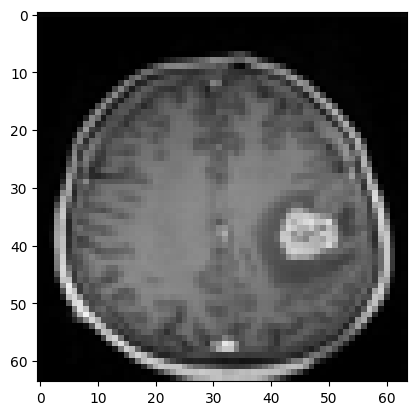

In [52]:
show_result('E:\Code\Deep Learning Project\Brain Tumor Detection Using Deep Learning\pred\pred8.jpg')

In [53]:
prediction=model.predict(x_test)
prediction=np.argmax(prediction,axis=1)

19/19 [==============================] - 0s 5ms/step


In [54]:
from sklearn.metrics import accuracy_score
accuracy_score(prediction,y_test)

0.9433333333333334

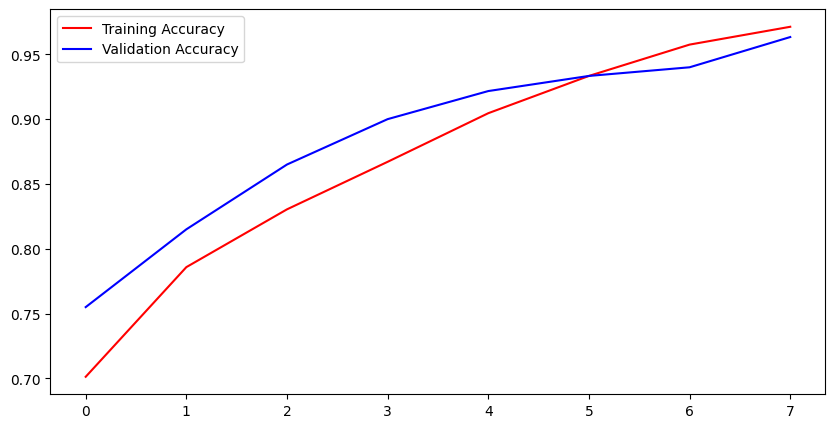

In [55]:
acc = history.history['accuracy']
val_acc = history.history['val_accuracy']
epochs = range(len(acc))
fig = plt.figure(figsize=(10,5))
plt.plot(epochs,acc,'r',label="Training Accuracy")
plt.plot(epochs,val_acc,'b',label="Validation Accuracy")
plt.legend(loc='upper left')
plt.show()

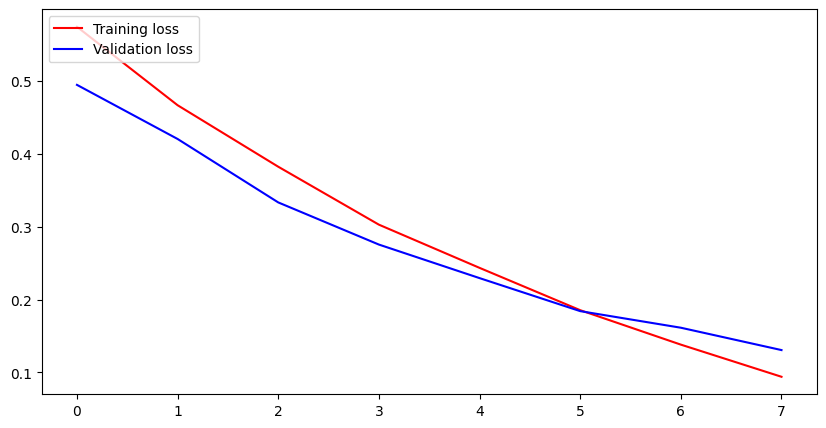

In [56]:
loss = history.history['loss']
val_loss = history.history['val_loss']
epochs = range(len(loss))
fig = plt.figure(figsize=(10,5))
plt.plot(epochs,loss,'r',label="Training loss")
plt.plot(epochs,val_loss,'b',label="Validation loss")
plt.legend(loc='upper left')
plt.show()

1/1 [==============================] - 0s 49ms/step
Tumor


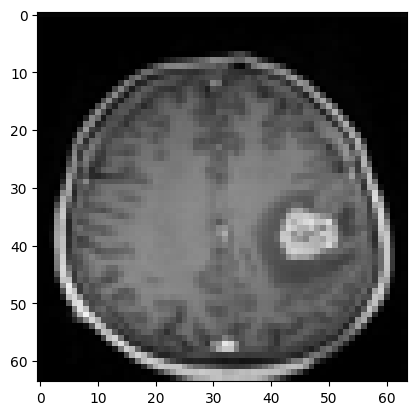

In [57]:
show_result('E:\Code\Deep Learning Project\Brain Tumor Detection Using Deep Learning\pred\pred8.jpg')
def show_result(address):
    model = load_model('BrainTumor10EpochsCategorical.h5')

    # Load and preprocess the image
    image = cv2.imread(address)
    img = Image.fromarray(image)
    img = img.resize((64, 64))
    img = np.array(img)
    
    input_img = np.expand_dims(img, axis=0) 
    
    # Predict the class probabilities
    probs = model.predict(input_img)
    
    # Get the predicted class index (class with the highest probability)
    predicted_class = np.argmax(probs)
    if predicted_class ==0:
        print("No Tumor")
    else:
        print("Tumor")

    plt.imshow(img)
    plt.show()
    
    #print("Predicted Class:", predicted_class)

1/1 [==============================] - 0s 53ms/step
No Tumor


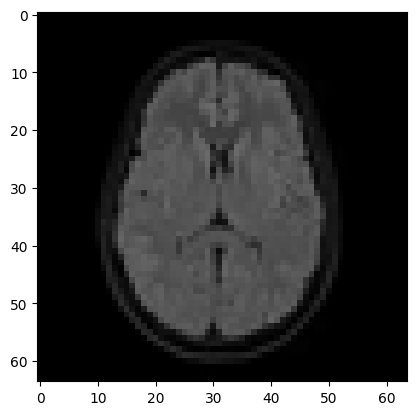

1/1 [==============================] - 0s 50ms/step
No Tumor


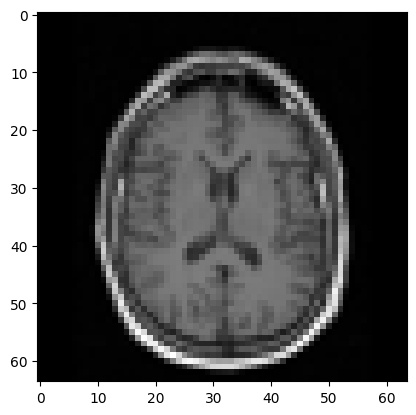

1/1 [==============================] - 0s 52ms/step
Tumor


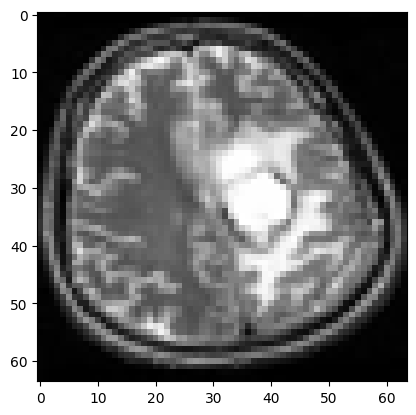

1/1 [==============================] - 0s 51ms/step
Tumor


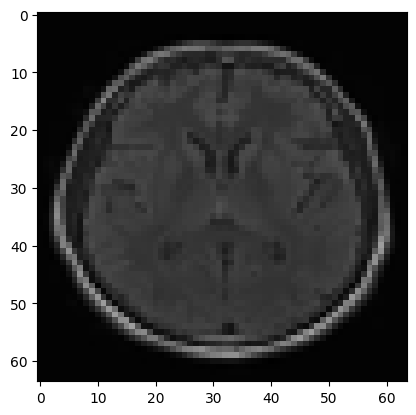

1/1 [==============================] - 0s 51ms/step
No Tumor


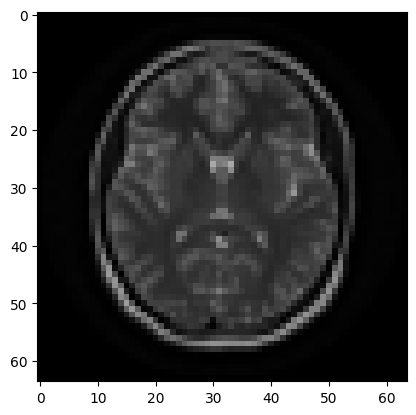

1/1 [==============================] - 0s 67ms/step
Tumor


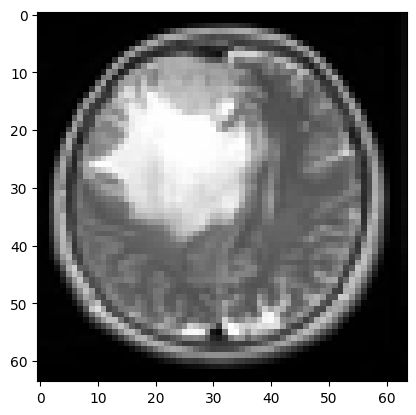

1/1 [==============================] - 0s 51ms/step
No Tumor


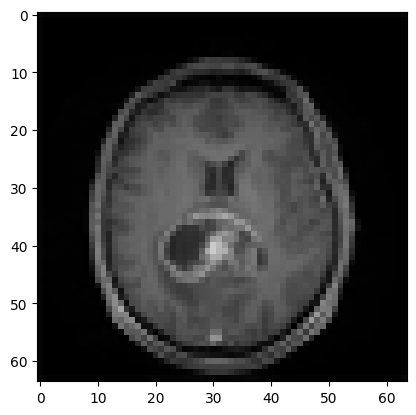

1/1 [==============================] - 0s 52ms/step
Tumor


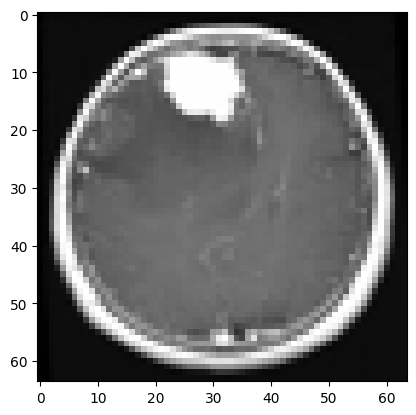

1/1 [==============================] - 0s 69ms/step
Tumor


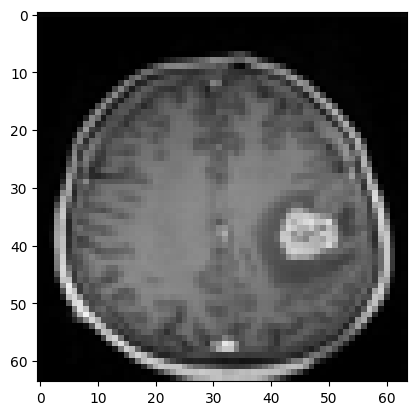

1/1 [==============================] - 0s 89ms/step
No Tumor


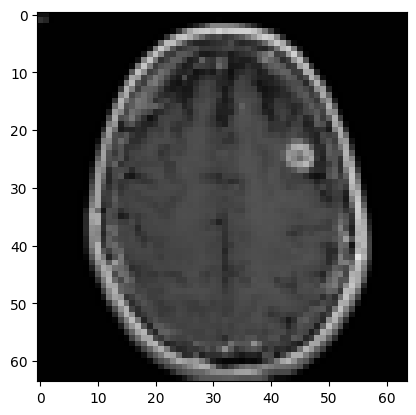

1/1 [==============================] - 0s 84ms/step
No Tumor


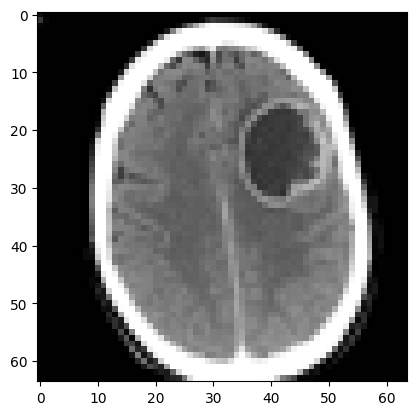

1/1 [==============================] - 0s 132ms/step
Tumor


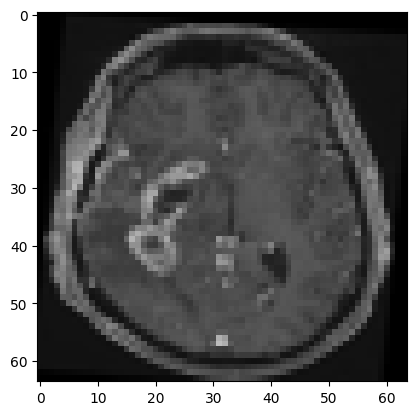

1/1 [==============================] - 0s 67ms/step
No Tumor


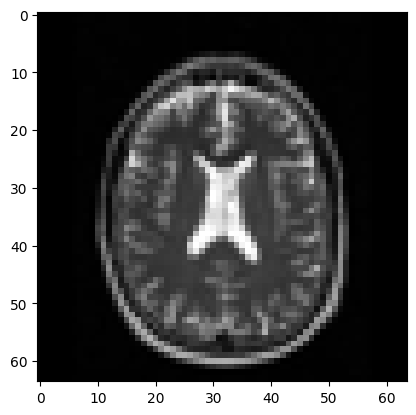

1/1 [==============================] - 0s 50ms/step
Tumor


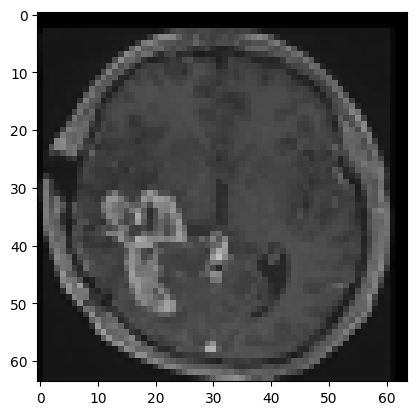

1/1 [==============================] - 0s 53ms/step
Tumor


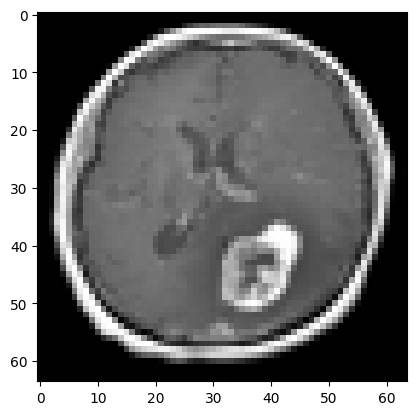

1/1 [==============================] - 0s 91ms/step
No Tumor


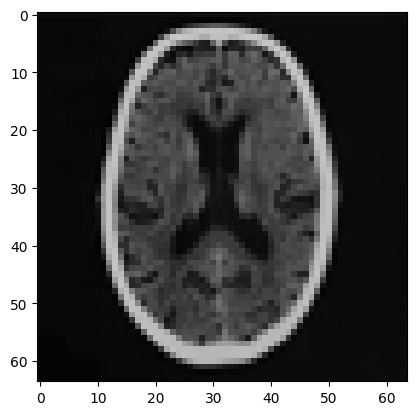

1/1 [==============================] - 0s 52ms/step
No Tumor


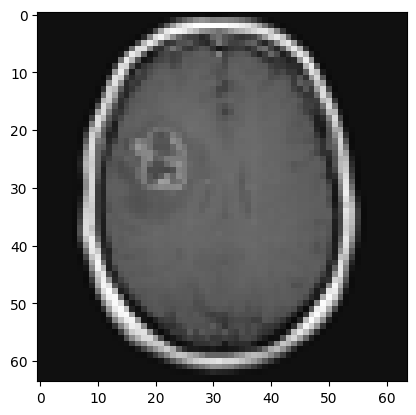

1/1 [==============================] - 0s 63ms/step
Tumor


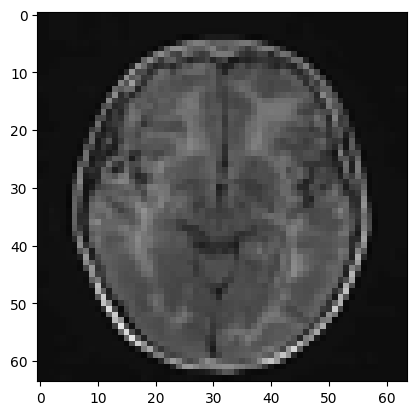

1/1 [==============================] - 0s 51ms/step
Tumor


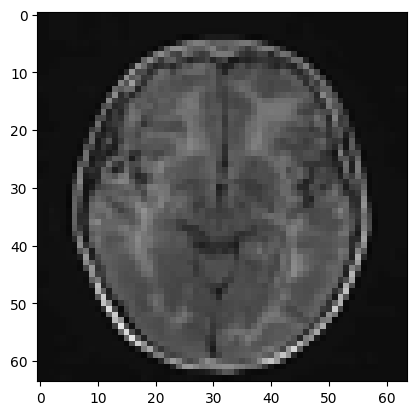

1/1 [==============================] - 0s 52ms/step
No Tumor


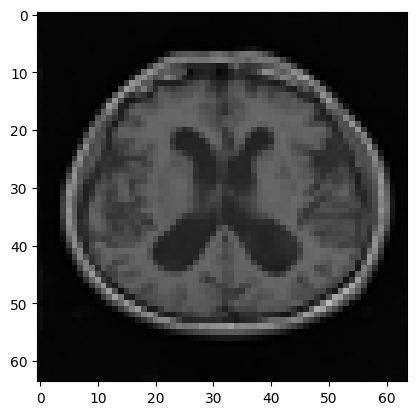

1/1 [==============================] - 0s 50ms/step
No Tumor


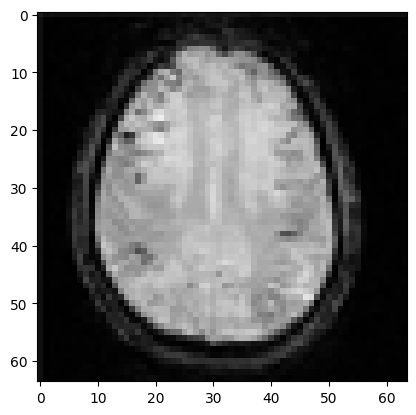

1/1 [==============================] - 0s 87ms/step
No Tumor


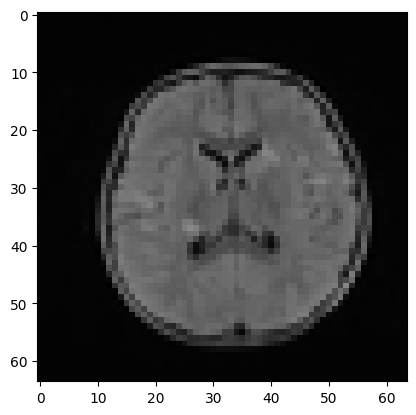

1/1 [==============================] - 0s 54ms/step
Tumor


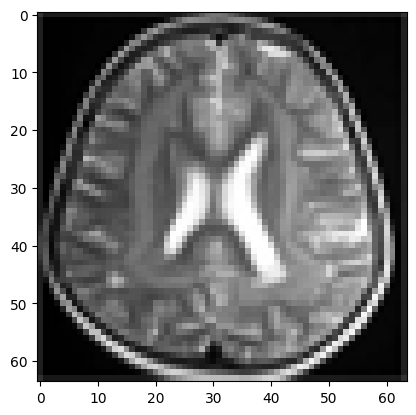

1/1 [==============================] - 0s 48ms/step
Tumor


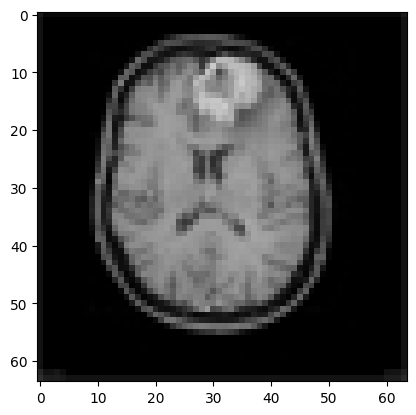

1/1 [==============================] - 0s 52ms/step
No Tumor


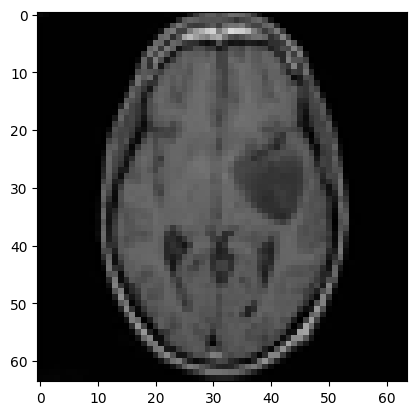

1/1 [==============================] - 0s 50ms/step
No Tumor


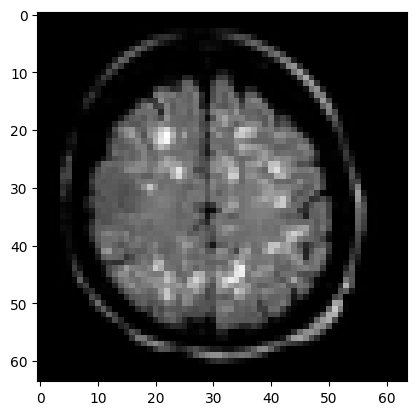

1/1 [==============================] - 0s 74ms/step
No Tumor


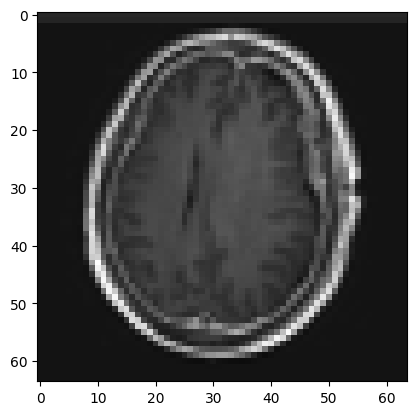

1/1 [==============================] - 0s 52ms/step
Tumor


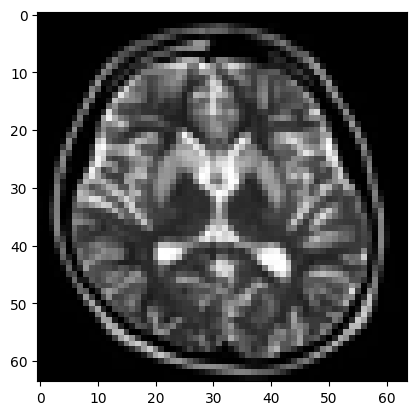

1/1 [==============================] - 0s 52ms/step
Tumor


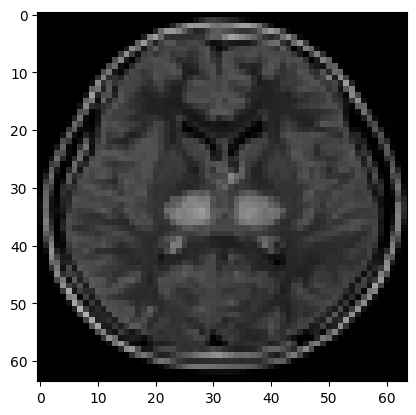

1/1 [==============================] - 0s 50ms/step
No Tumor


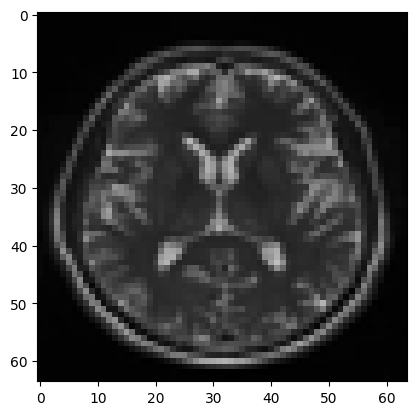

1/1 [==============================] - 0s 72ms/step
Tumor


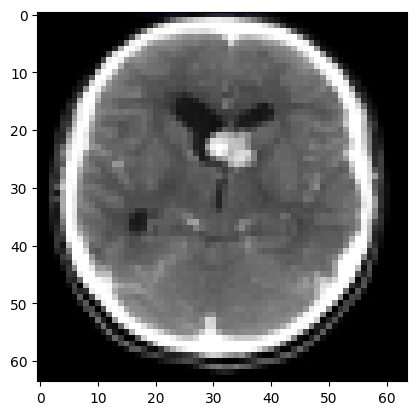

1/1 [==============================] - 0s 121ms/step
Tumor


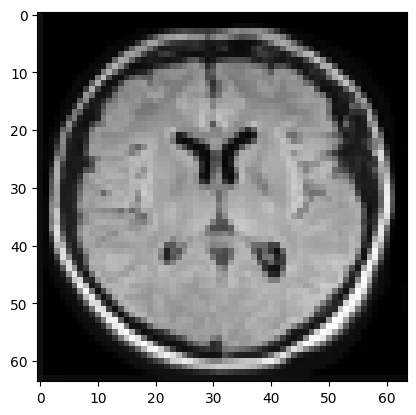

1/1 [==============================] - 0s 51ms/step
Tumor


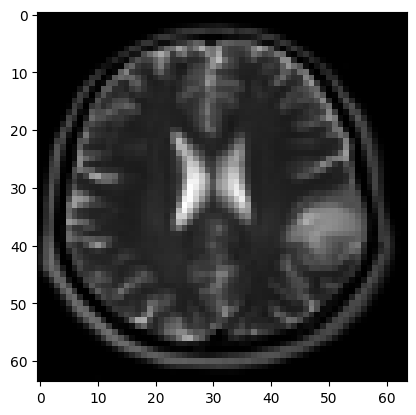

1/1 [==============================] - 0s 83ms/step
No Tumor


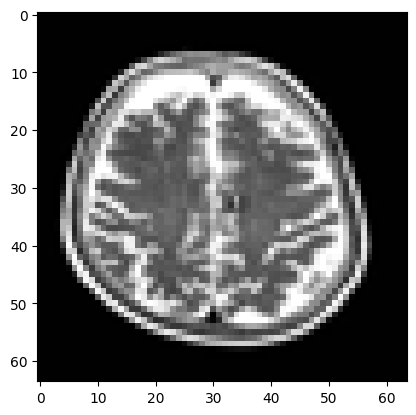

1/1 [==============================] - 0s 52ms/step
Tumor


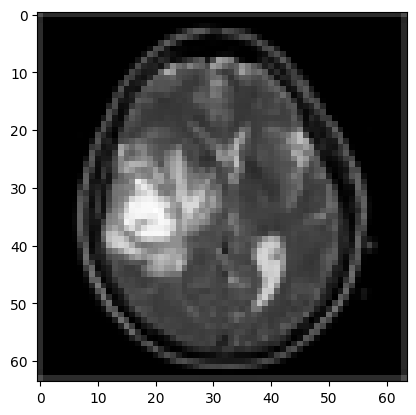

1/1 [==============================] - 0s 96ms/step
No Tumor


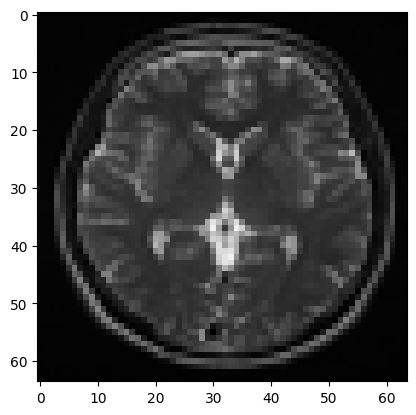

1/1 [==============================] - 0s 50ms/step
No Tumor


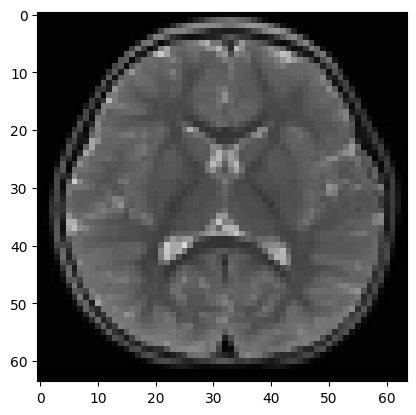

1/1 [==============================] - 0s 59ms/step
No Tumor


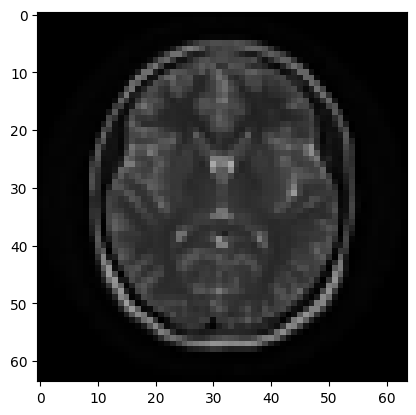

1/1 [==============================] - 0s 51ms/step
No Tumor


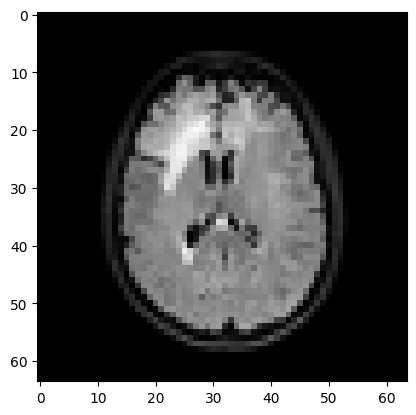

1/1 [==============================] - 0s 105ms/step
Tumor


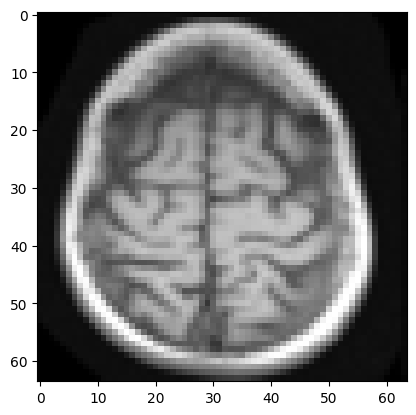

1/1 [==============================] - 0s 79ms/step
No Tumor


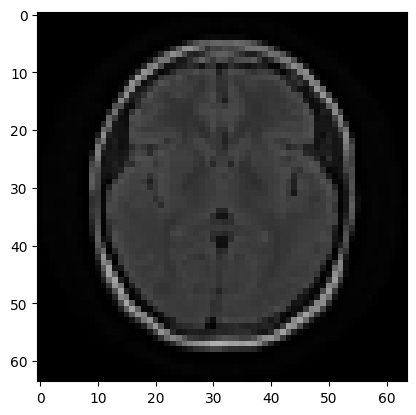

1/1 [==============================] - 0s 50ms/step
No Tumor


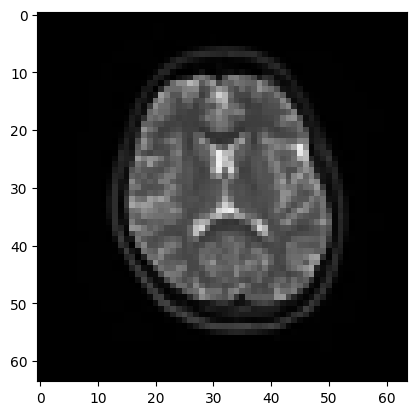

1/1 [==============================] - 0s 59ms/step
No Tumor


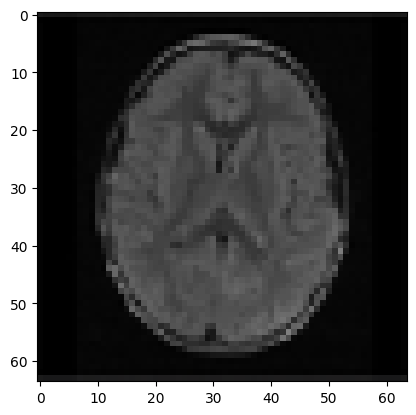

1/1 [==============================] - 0s 51ms/step
No Tumor


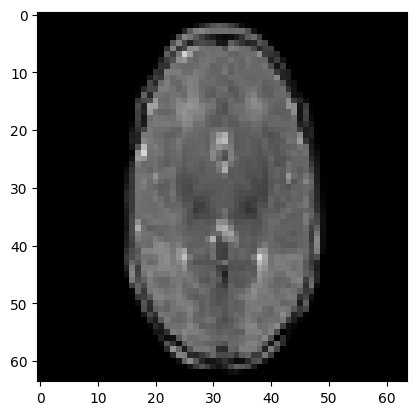

1/1 [==============================] - 0s 48ms/step
No Tumor


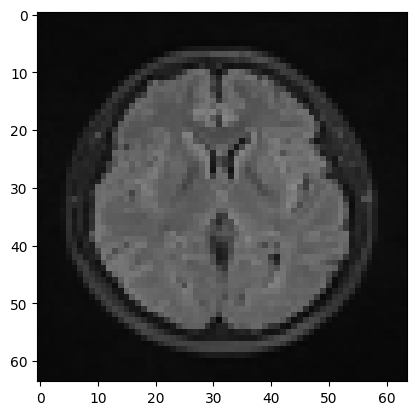

1/1 [==============================] - 0s 50ms/step
Tumor


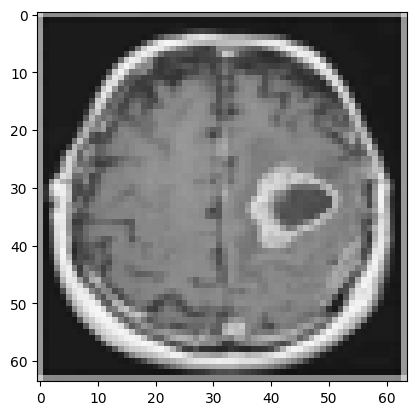

1/1 [==============================] - 0s 49ms/step
No Tumor


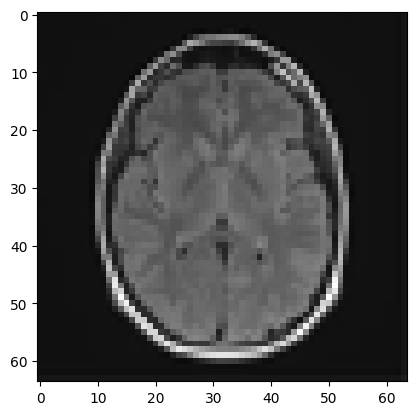

1/1 [==============================] - 0s 48ms/step
No Tumor


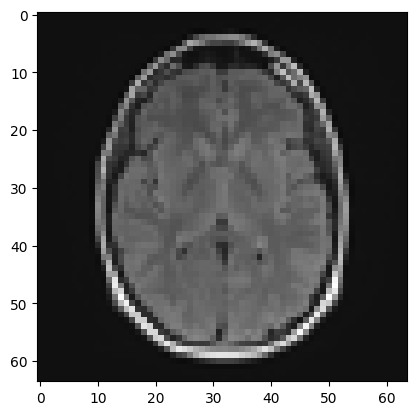

1/1 [==============================] - 0s 81ms/step
No Tumor


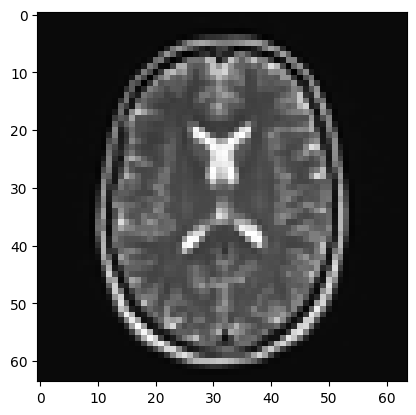

1/1 [==============================] - 0s 74ms/step
No Tumor


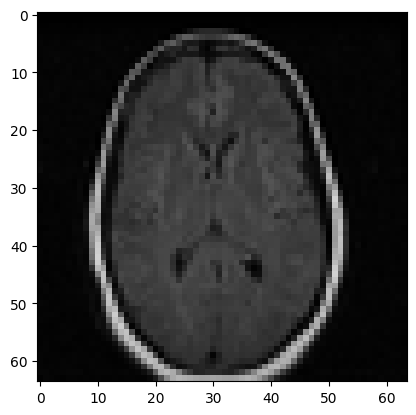

1/1 [==============================] - 0s 102ms/step
No Tumor


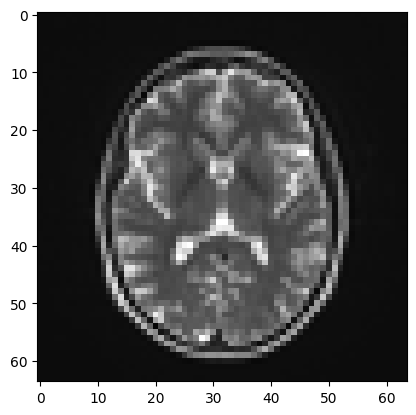

1/1 [==============================] - 0s 149ms/step
Tumor


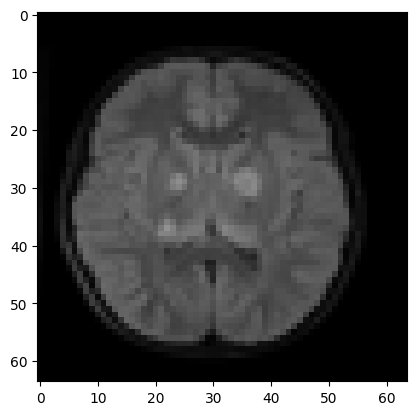

1/1 [==============================] - 0s 50ms/step
No Tumor


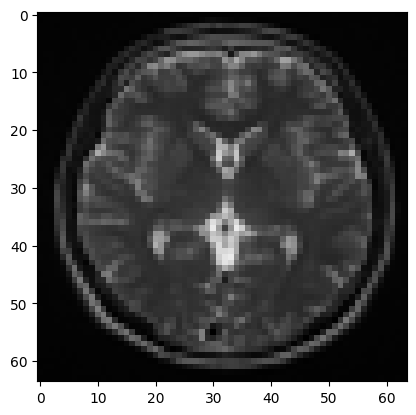

1/1 [==============================] - 0s 50ms/step
No Tumor


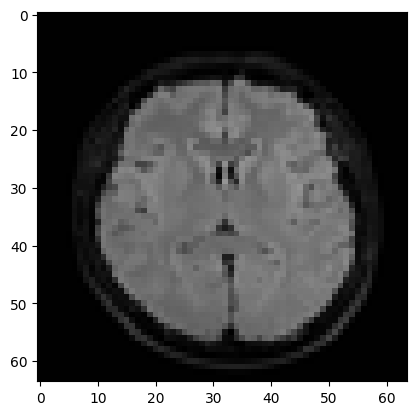

1/1 [==============================] - 0s 61ms/step
Tumor


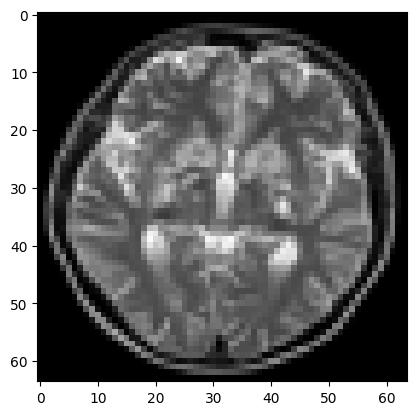

1/1 [==============================] - 0s 57ms/step
Tumor


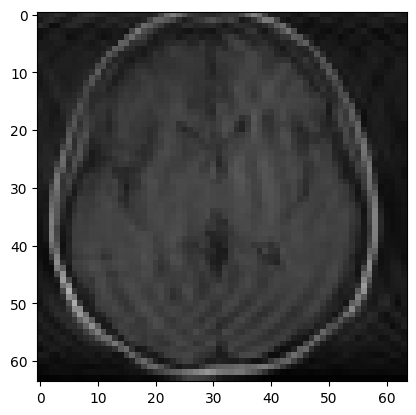

1/1 [==============================] - 0s 48ms/step
Tumor


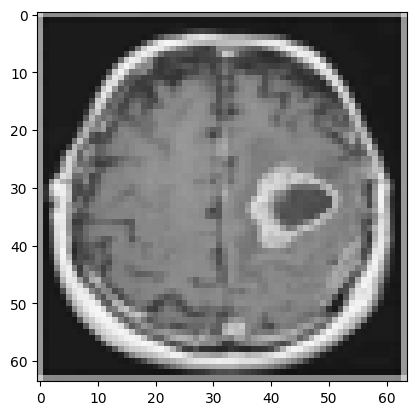

1/1 [==============================] - 0s 118ms/step
Tumor


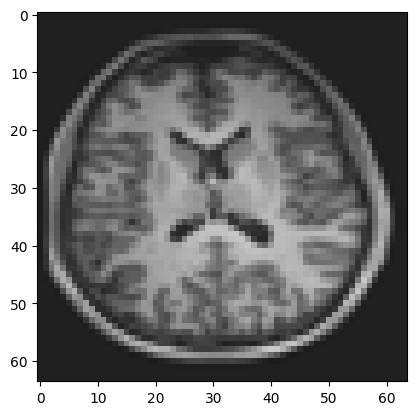

1/1 [==============================] - 0s 73ms/step
No Tumor


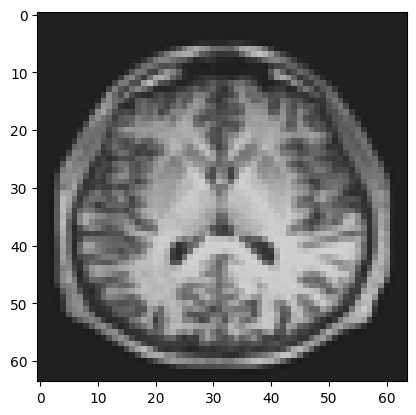

1/1 [==============================] - 0s 53ms/step
No Tumor


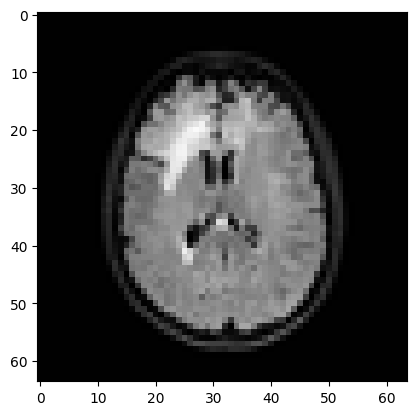

In [58]:
for i in range(0,60):
    model = load_model('BrainTumor10EpochsCategorical.h5')
    address='E:\Code\Deep Learning Project\Brain Tumor Detection Using Deep Learning\pred\pred'+str(i)+'.jpg'
    # Load and preprocess the image
    # print(address)
    image = cv2.imread(address)
    img = Image.fromarray(image)
    img = img.resize((64, 64))
    img = np.array(img)
    
    input_img = np.expand_dims(img, axis=0) 
    
    # Predict the class probabilities
    probs = model.predict(input_img)
    
    # Get the predicted class index (class with the highest probability)
    predicted_class = np.argmax(probs)
    if predicted_class ==0:
        print("No Tumor")
    else:
        print("Tumor")

    plt.imshow(img)
    plt.show()